In [4]:
import pandas as pd 
import seaborn as sns
import kagglehub

In [5]:
from bootcampviztools import plot_combined_graphs, pinta_distribucion_categoricas, plot_categorical_relationship_fin,\
      plot_grouped_boxplots,plot_grouped_histograms, grafico_dispersion_con_correlacion, plot_categorical_numerical_relationship
from scipy.stats import pearsonr

In [6]:
import numpy as np
import matplotlib.pyplot as plt

In [7]:
path = kagglehub.dataset_download(
    "amitanshjoshi/spotify-1million-tracks"
)

In [6]:
def card_tipo(df,umbral_categoria = 10, umbral_continua = 30):
    # Primera parte: Preparo el dataset con cardinalidades, % variación cardinalidad, y tipos
    df_temp = pd.DataFrame([df.nunique(), df.nunique()/len(df) * 100, df.dtypes]) # Cardinaliad y porcentaje de variación de cardinalidad
    df_temp = df_temp.T # Como nos da los valores de las columnas en columnas, y quiero que estas sean filas, la traspongo
    df_temp = df_temp.rename(columns = {0: "Card", 1: "%_Card", 2: "Tipo"}) # Cambio el nombre de la transposición anterior para que tengan más sentido, y uso asignación en vez de inplace = True (esto es arbitrario para el tamaño de este dataset)

    # Corrección para cuando solo tengo un valor
    df_temp.loc[df_temp.Card == 1, "%_Card"] = 0.00

    # Creo la columna de sugerenica de tipo de variable, empiezo considerando todas categóricas pero podría haber empezado por cualquiera, siempre que adapte los filtros siguientes de forma correspondiente
    df_temp["tipo_sugerido"] = "Categorica"
    df_temp.loc[df_temp["Card"] == 2, "tipo_sugerido"] = "Binaria"
    df_temp.loc[df_temp["Card"] >= umbral_categoria, "tipo_sugerido"] = "Numerica discreta"
    df_temp.loc[df_temp["%_Card"] >= umbral_continua, "tipo_sugerido"] = "Numerica continua"
    # Ojo los filtros aplicados cumplen con el enunciado pero no siguen su orden y planteamiento

    return df_temp

In [8]:
npath=path+'/spotify_data.csv'
archivo=pd.read_csv(npath, sep=',',index_col=0)
archivo

,artist_name,track_name,track_id,popularity,year,genre,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature
0,Jason Mraz,I Won't Give Up,53QF56cjZA9RTuuMZDrSA6,68,2012,acoustic,0.483,0.303,4,-10.058,1,0.0429,0.6940,0.000000,0.1150,0.1390,133.406,240166,3
1,Jason Mraz,93 Million Miles,1s8tP3jP4GZcyHDsjvw218,50,2012,acoustic,0.572,0.454,3,-10.286,1,0.0258,0.4770,0.000014,0.0974,0.5150,140.182,216387,4
2,Joshua Hyslop,Do Not Let Me Go,7BRCa8MPiyuvr2VU3O9W0F,57,2012,acoustic,0.409,0.234,3,-13.711,1,0.0323,0.3380,0.000050,0.0895,0.1450,139.832,158960,4
3,Boyce Avenue,Fast Car,63wsZUhUZLlh1OsyrZq7sz,58,2012,acoustic,0.392,0.251,10,-9.845,1,0.0363,0.8070,0.000000,0.0797,0.5080,204.961,304293,4
4,Andrew Belle,Sky's Still Blue,6nXIYClvJAfi6ujLiKqEq8,54,2012,acoustic,0.430,0.791,6,-5.419,0,0.0302,0.0726,0.019300,0.1100,0.2170,171.864,244320,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1473391,Nicola Conte,Black Spirits,0m27F0IGHLGAWhqd6ccYst,4,2011,trip-hop,0.373,0.742,10,-6.453,0,0.0736,0.3250,0.000141,0.1590,0.5220,107.951,344013,3
1473392,Nicola Conte,Quiet Dawn,6er9p611eHEcUCU50j7D57,3,2011,trip-hop,0.516,0.675,7,-7.588,0,0.0326,0.7880,0.000129,0.1300,0.2640,119.897,285067,4
1473393,Amon Tobin,Morning Ms Candis,7jsMMqxy1tt0rH5FzYcZTQ,2,2011,trip-hop,0.491,0.440,5,-8.512,1,0.0274,0.4770,0.003130,0.0936,0.0351,100.076,214253,4
1473394,Peace Orchestra,Happy Christmas (War Is Over),77lA1InUaXztuRk2vOzD1S,0,2011,trip-hop,0.480,0.405,0,-13.343,1,0.0276,0.4310,0.000063,0.1250,0.2020,133.885,239133,3


In [8]:
archivo.columns

Index(['artist_name', 'track_name', 'track_id', 'popularity', 'year', 'genre',
       'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness',
       'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo',
       'duration_ms', 'time_signature'],
      dtype='str')

In [ ]:
archivo.columns
archivo=archivo[[
        'artist_name', 'track_name', 'track_id', 'popularity', 'genre','year',
        'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness',
        'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo',
        'duration_ms', 'time_signature']]

In [10]:
df1 = archivo.groupby('year', as_index=False).median(numeric_only=True)
df1=df1.drop(columns=['key','time_signature','mode'])
df1


,year,popularity,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
0,2000,6.0,0.542,0.647,-8.5965,0.0477,0.2210,0.001480,0.135,0.518,118.6615,233933.0
1,2001,7.0,0.540,0.641,-8.4450,0.0477,0.2220,0.001550,0.135,0.488,117.9920,234400.0
2,2002,8.0,0.548,0.666,-8.0930,0.0486,0.1850,0.001490,0.137,0.504,119.0930,236566.5
3,2003,8.0,0.539,0.677,-7.9335,0.0487,0.1820,0.001460,0.137,0.492,119.8215,233667.0
4,2004,8.0,0.540,0.687,-7.6820,0.0492,0.1810,0.000961,0.139,0.491,119.9740,235036.0
5,2005,10.0,0.538,0.682,-7.8290,0.0494,0.1690,0.001350,0.139,0.485,120.0730,234381.0
6,2006,9.0,0.544,0.683,-7.7390,0.0503,0.1610,0.001440,0.134,0.485,120.7515,236107.0
7,2007,10.0,0.545,0.697,-7.5610,0.0507,0.1560,0.001240,0.136,0.469,121.9260,236773.0
8,2008,10.0,0.547,0.702,-7.4580,0.0510,0.1270,0.001960,0.137,0.469,123.5705,235867.0
9,2009,11.0,0.548,0.700,-7.3930,0.0504,0.1270,0.002600,0.136,0.458,123.6230,236587.0


In [16]:
columnas = archivo.select_dtypes(include='number').columns.drop(
    ['popularity', 'year', 'key', 'mode', 'time_signature']
)

Q1 = archivo[columnas].quantile(0.25)
Q3 = archivo[columnas].quantile(0.75)

IQR = Q3 - Q1
lim_inf = Q1 - 1.5 * IQR
lim_sup = Q3 + 1.5 * IQR
outliers = archivo[
    (archivo[columnas] < lim_inf) |
    (archivo[columnas] > lim_sup)
]

print(outliers.sum())


artist_name                      
track_name                       
track_id                         
popularity                    0.0
year                          0.0
genre                            
danceability                  0.0
energy                        0.0
key                           0.0
loudness             -1883150.211
mode                          0.0
speechiness             48727.578
acousticness                  0.0
instrumentalness              0.0
liveness                72123.624
valence                       0.0
tempo                  889542.922
duration_ms         37407555785.0
time_signature                0.0
dtype: object


In [12]:
archivo

,artist_name,track_name,track_id,popularity,genre,year,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature
0,Jason Mraz,I Won't Give Up,53QF56cjZA9RTuuMZDrSA6,68,acoustic,2012,0.483,0.303,4,-10.058,1,0.0429,0.6940,0.000000,0.1150,0.1390,133.406,240166,3
1,Jason Mraz,93 Million Miles,1s8tP3jP4GZcyHDsjvw218,50,acoustic,2012,0.572,0.454,3,-10.286,1,0.0258,0.4770,0.000014,0.0974,0.5150,140.182,216387,4
2,Joshua Hyslop,Do Not Let Me Go,7BRCa8MPiyuvr2VU3O9W0F,57,acoustic,2012,0.409,0.234,3,-13.711,1,0.0323,0.3380,0.000050,0.0895,0.1450,139.832,158960,4
3,Boyce Avenue,Fast Car,63wsZUhUZLlh1OsyrZq7sz,58,acoustic,2012,0.392,0.251,10,-9.845,1,0.0363,0.8070,0.000000,0.0797,0.5080,204.961,304293,4
4,Andrew Belle,Sky's Still Blue,6nXIYClvJAfi6ujLiKqEq8,54,acoustic,2012,0.430,0.791,6,-5.419,0,0.0302,0.0726,0.019300,0.1100,0.2170,171.864,244320,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1473391,Nicola Conte,Black Spirits,0m27F0IGHLGAWhqd6ccYst,4,trip-hop,2011,0.373,0.742,10,-6.453,0,0.0736,0.3250,0.000141,0.1590,0.5220,107.951,344013,3
1473392,Nicola Conte,Quiet Dawn,6er9p611eHEcUCU50j7D57,3,trip-hop,2011,0.516,0.675,7,-7.588,0,0.0326,0.7880,0.000129,0.1300,0.2640,119.897,285067,4
1473393,Amon Tobin,Morning Ms Candis,7jsMMqxy1tt0rH5FzYcZTQ,2,trip-hop,2011,0.491,0.440,5,-8.512,1,0.0274,0.4770,0.003130,0.0936,0.0351,100.076,214253,4
1473394,Peace Orchestra,Happy Christmas (War Is Over),77lA1InUaXztuRk2vOzD1S,0,trip-hop,2011,0.480,0.405,0,-13.343,1,0.0276,0.4310,0.000063,0.1250,0.2020,133.885,239133,3


In [13]:
card_tipo(archivo)

,Card,%_Card,Tipo,tipo_sugerido
artist_name,64158,5.531988,str,Numerica discreta
track_name,882360,76.080996,str,Numerica continua
track_id,1159764,100.0,str,Numerica continua
popularity,98,0.00845,int64,Numerica discreta
genre,82,0.00707,str,Numerica discreta
year,24,0.002069,int64,Numerica discreta
danceability,1364,0.11761,float64,Numerica discreta
energy,3116,0.268675,float64,Numerica discreta
key,12,0.001035,int64,Numerica discreta
loudness,37368,3.222035,float64,Numerica discreta


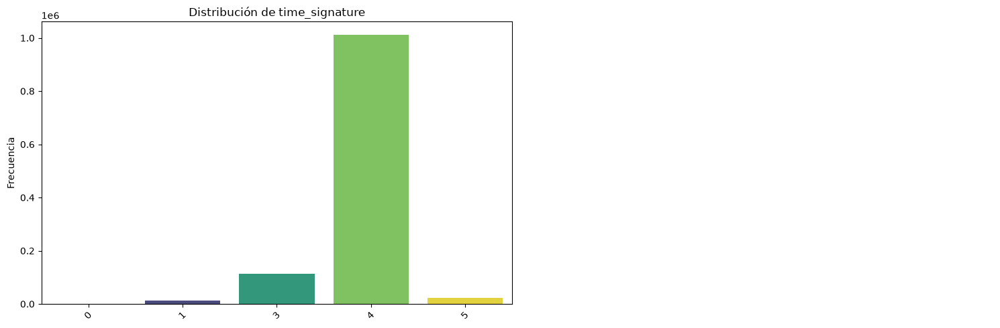

In [14]:
pinta_distribucion_categoricas(archivo, ['time_signature'])

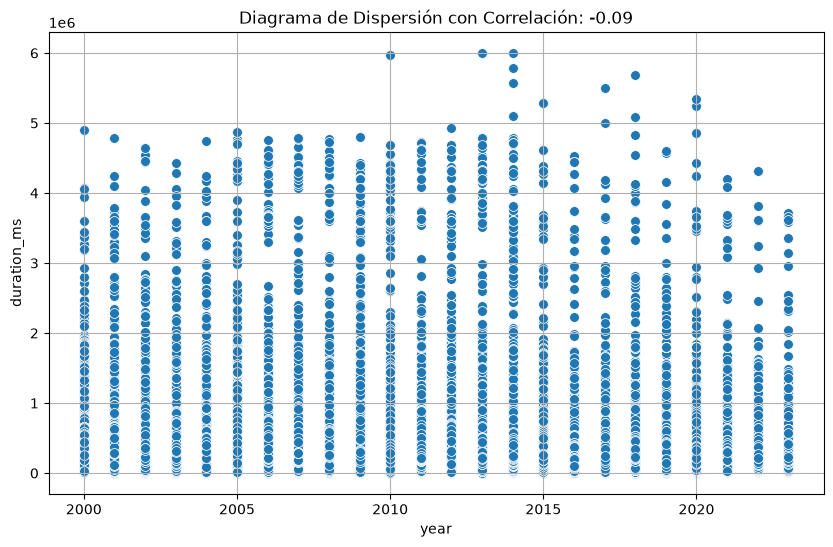

In [17]:
grafico_dispersion_con_correlacion(archivo,"year","duration_ms", mostrar_correlacion= True)

In [16]:
pearsonr(archivo["year"], archivo["duration_ms"])

PearsonRResult(statistic=np.float64(-0.09037138976606562), pvalue=np.float64(0.0))

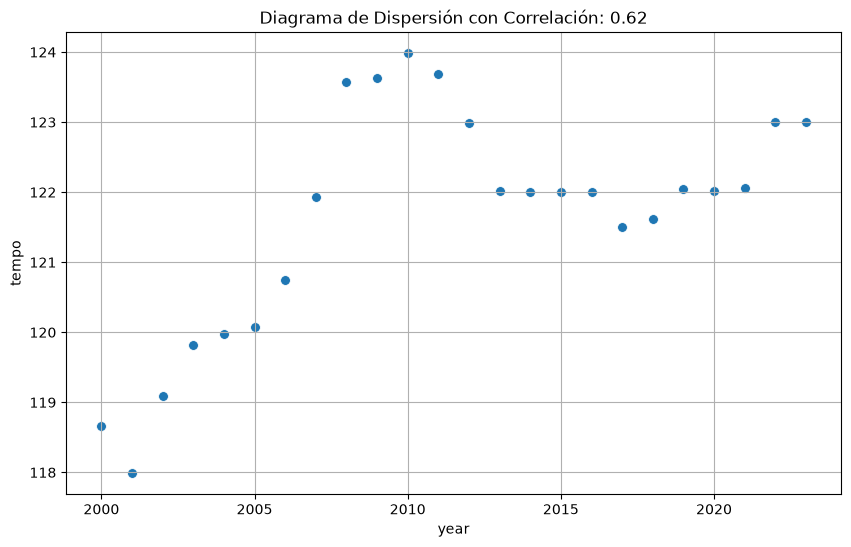

In [17]:
grafico_dispersion_con_correlacion(df1,"year","tempo", mostrar_correlacion= True)

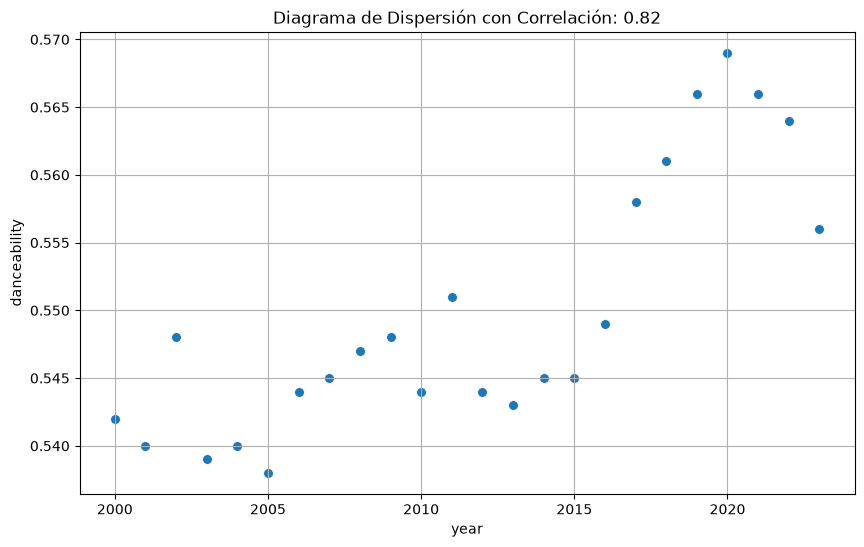

In [18]:
grafico_dispersion_con_correlacion(df1,"year","danceability", mostrar_correlacion= True)

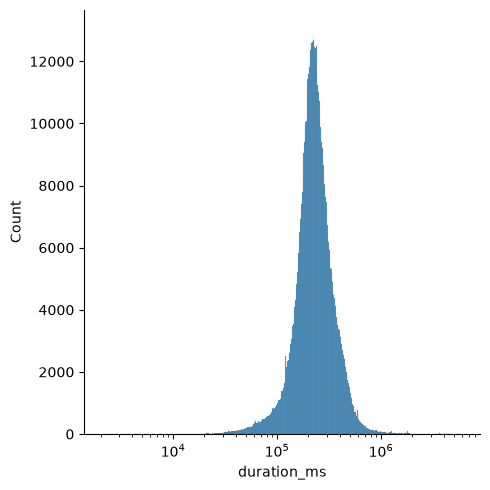

In [19]:
sns.displot(archivo['duration_ms'],log_scale=True);

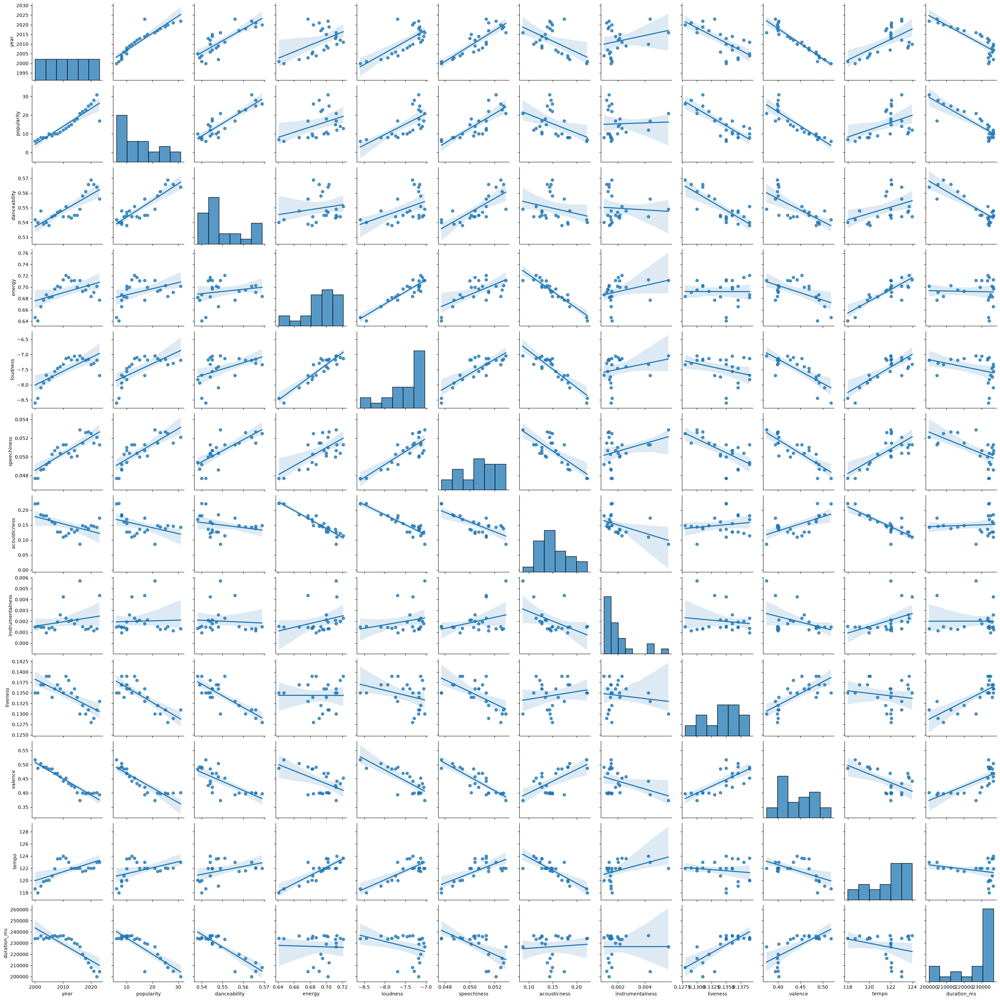

In [20]:
sns.pairplot(df1,
             kind='reg');

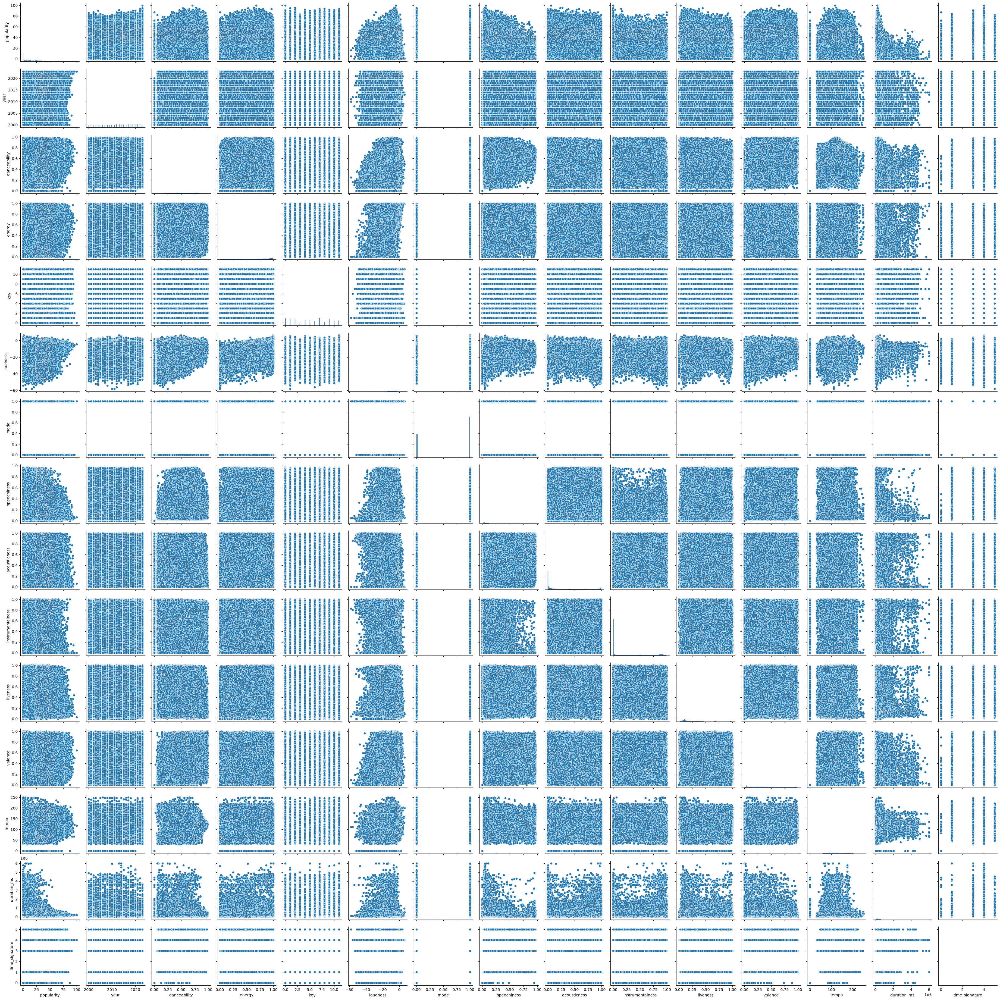

In [21]:
sns.pairplot(archivo)

In [22]:
'''
tempo tiene celdas con valores 0. No tiene sentido, por lo que se 
llevara a cabo la mediana para saber el valor mas habitual posible para cada cancion por genero

'''

archivo['tempo']= archivo['tempo'].replace(0, np.nan)

In [23]:


medianas = archivo.groupby('genre')['tempo'].median()

archivo['tempo'] = archivo['tempo'].fillna(archivo['genre'].map(medianas))




In [24]:
#vamos a comprobar que no hay tempos a 0
archivo.where(archivo.tempo==0).dropna()

,artist_name,track_name,track_id,popularity,genre,year,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature


In [25]:
archivo.where(archivo.valence==0).dropna()

,artist_name,track_name,track_id,popularity,genre,year,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature
3718,Yellow Eyes,Cathedral,0WDHljGtFAqFuJczQVjAgl,31.0,black-metal,2012.0,0.0,0.000020,7.0,-6.884,1.0,0.0,0.1220,0.647000,0.1450,0.0,122.4370,282593.0,0.0
9177,Benjamin Britten,"Gloriana, Op. 53: Choral Dances: No. 3. Time a...",70rBFLXNmCGM0fjkb0lui1,17.0,classical,2012.0,0.0,0.093500,5.0,-21.989,1.0,0.0,0.9920,0.000273,0.0711,0.0,102.3190,78760.0,0.0
10557,Papa Razzi and the Photogs,"Jeremy Renner, You Are a Good Actor, Yes You Are!",51vaFBGtC58ZDbhPMkBsDg,15.0,comedy,2012.0,0.0,0.217000,7.0,-11.763,1.0,0.0,0.9140,0.000000,0.2680,0.0,93.7280,70867.0,0.0
21277,Bahamas,Any Other Way,0yBMqUEsYzvcXt4zjBVSFI,21.0,folk,2012.0,0.0,0.225000,0.0,-13.201,1.0,0.0,0.8780,0.000000,0.2810,0.0,117.1805,63227.0,0.0
27315,Napalm Death,Your Achievement,12wI8ek7n94nVBxw3BUvo4,0.0,grindcore,2012.0,0.0,0.427000,0.0,-8.277,0.0,0.0,0.0175,0.374000,0.0000,0.0,115.9320,6467.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1465439,Nature Sounds,Powerful Cleansing Rain,5hBaqTQSDhxfTbxKBaOFcG,12.0,sleep,2011.0,0.0,0.000866,5.0,-11.721,1.0,0.0,0.1500,0.654000,0.5030,0.0,89.9770,2015766.0,0.0
1465752,Nature Sounds,Powerful Niagara Falls,37jVbNMj6QcNeGZdJ5PQKH,6.0,sleep,2011.0,0.0,0.000866,5.0,-11.721,1.0,0.0,0.1500,0.654000,0.5030,0.0,89.9770,2015766.0,0.0
1465761,Thunderstorm,Cicadas After the Rain,17gITIT8vgcrh8UHOrjh6G,7.0,sleep,2011.0,0.0,0.003320,3.0,-38.975,1.0,0.0,0.0159,0.555000,0.3230,0.0,89.9770,413363.0,0.0
1468302,Alonso Lobo,Lamentations Ieremiae Prophetae: Teth III,0dhFVBcsTjDMsozdf0i6Or,12.0,spanish,2011.0,0.0,0.042100,11.0,-29.392,0.0,0.0,0.9920,0.931000,0.0752,0.0,122.9580,53293.0,0.0


In [26]:
l=[]
for i in archivo:
    Nan=archivo.shape[0]-archivo[[str(i)]].count().iloc[0]
    f=Nan/archivo.shape[0]*100
    l.append(f'en la comlumna {i} hay un {f}% de nan')
for i in l:
    print(i)

en la comlumna artist_name hay un 0.0012933665814769213% de nan
en la comlumna track_name hay un 8.622443876512808e-05% de nan
en la comlumna track_id hay un 0.0% de nan
en la comlumna popularity hay un 0.0% de nan
en la comlumna genre hay un 0.0% de nan
en la comlumna year hay un 0.0% de nan
en la comlumna danceability hay un 0.0% de nan
en la comlumna energy hay un 0.0% de nan
en la comlumna key hay un 0.0% de nan
en la comlumna loudness hay un 0.0% de nan
en la comlumna mode hay un 0.0% de nan
en la comlumna speechiness hay un 0.0% de nan
en la comlumna acousticness hay un 0.0% de nan
en la comlumna instrumentalness hay un 0.0% de nan
en la comlumna liveness hay un 0.0% de nan
en la comlumna valence hay un 0.0% de nan
en la comlumna tempo hay un 0.0% de nan
en la comlumna duration_ms hay un 0.0% de nan
en la comlumna time_signature hay un 0.0% de nan


<Axes: >

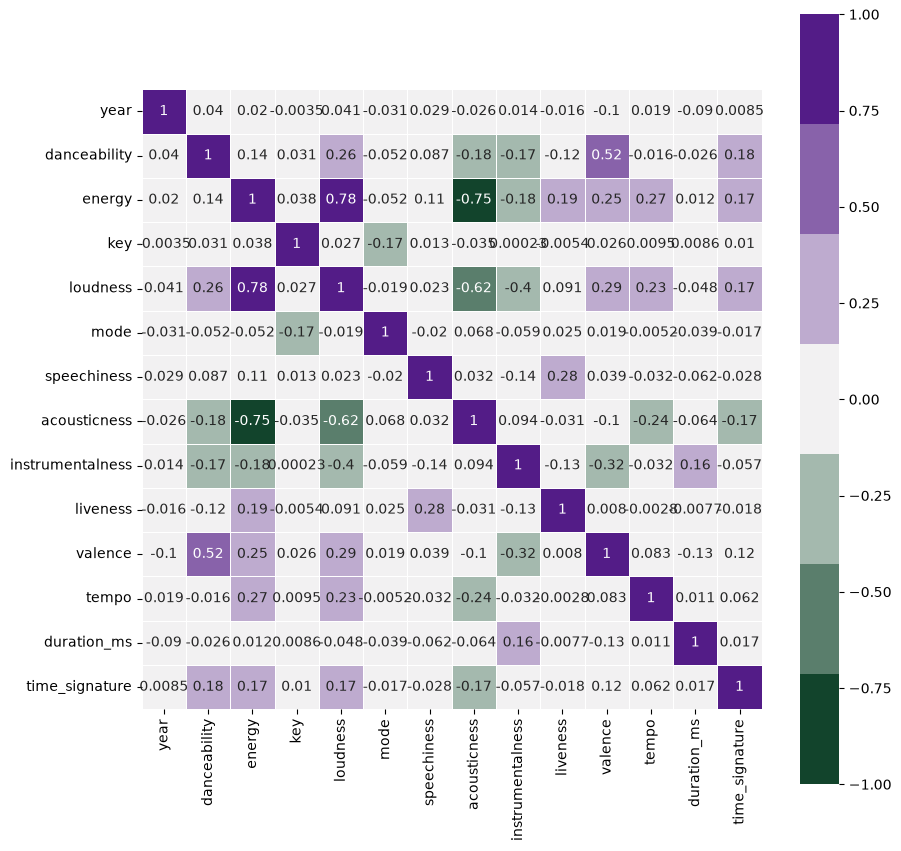

In [101]:
plt.figure(figsize=(10, 10))

sns.heatmap(
    archivo.iloc[:,5:].corr(),
    vmin=-1,
    vmax=1,
    cmap=sns.diverging_palette(145, 280, s=85, l=25, n=7),
    annot=True,
    square=True,
    linewidths=.5
)

<Axes: >

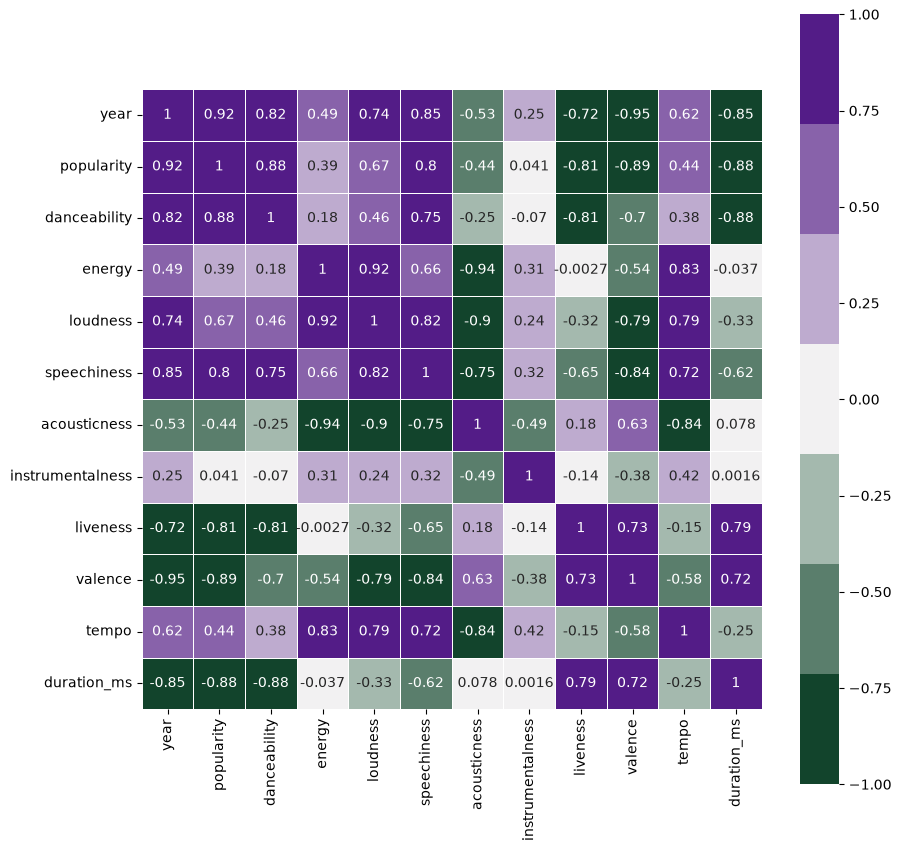

In [47]:
plt.figure(figsize=(10, 10))

sns.heatmap(
    df1.corr(),
    vmin=-1,
    vmax=1,
    cmap=sns.diverging_palette(145, 280, s=85, l=25, n=7),
    annot=True,
    square=True,
    linewidths=.5
)

In [ ]:
df3=archivo.groupby('popularity')[['danceability','energy','loudness']].median().tail()
df3

,danceability,energy,loudness
popularity,,,
0,0.560,0.673,-8.606
1,0.566,0.714,-8.065
2,0.549,0.692,-8.214
3,0.539,0.688,-8.159
4,0.532,0.684,-8.167
...,...,...,...
93,0.801,0.806,-5.206
94,0.644,0.735,-5.747
95,0.531,0.525,-6.500


In [8]:

df2 = archivo.loc[archivo.groupby('year')['popularity'].idxmax()]
df2 = df2.sort_values('year')
df2=df2.drop(columns=['artist_name', 'track_name', 'track_id','genre'])
df2

,popularity,year,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature
651395,86,2000,0.949,0.661,5,-4.244,0,0.0572,0.030200,0.000000,0.0454,0.760,104.504,284200,4
771635,82,2001,0.417,0.934,7,-3.908,0,0.1190,0.000278,0.001500,0.1320,0.287,127.066,210240,4
825779,87,2002,0.908,0.669,7,-2.827,1,0.0738,0.002860,0.000000,0.2370,0.662,112.238,290320,4
894994,84,2003,0.496,0.863,9,-4.153,1,0.0381,0.004600,0.000000,0.6390,0.243,110.018,185587,4
952551,90,2004,0.637,0.678,0,-3.798,1,0.2660,0.209000,0.000000,0.1560,0.254,84.039,250760,4
995854,84,2005,0.778,0.824,10,-5.892,0,0.0707,0.284000,0.000000,0.4050,0.758,100.024,218093,4
1062594,82,2006,0.808,0.970,10,-6.098,0,0.0506,0.056900,0.000061,0.1540,0.868,114.328,242293,4
1145378,80,2007,0.520,0.852,0,-5.866,1,0.0543,0.002370,0.000058,0.0733,0.234,140.267,253587,4
1244818,80,2008,0.542,0.905,9,-5.653,1,0.0540,0.001720,0.010400,0.1360,0.374,153.398,203347,4
1296635,81,2009,0.491,0.956,11,-1.538,1,0.3920,0.029500,0.000000,0.4600,0.811,173.585,276920,4


<Axes: >

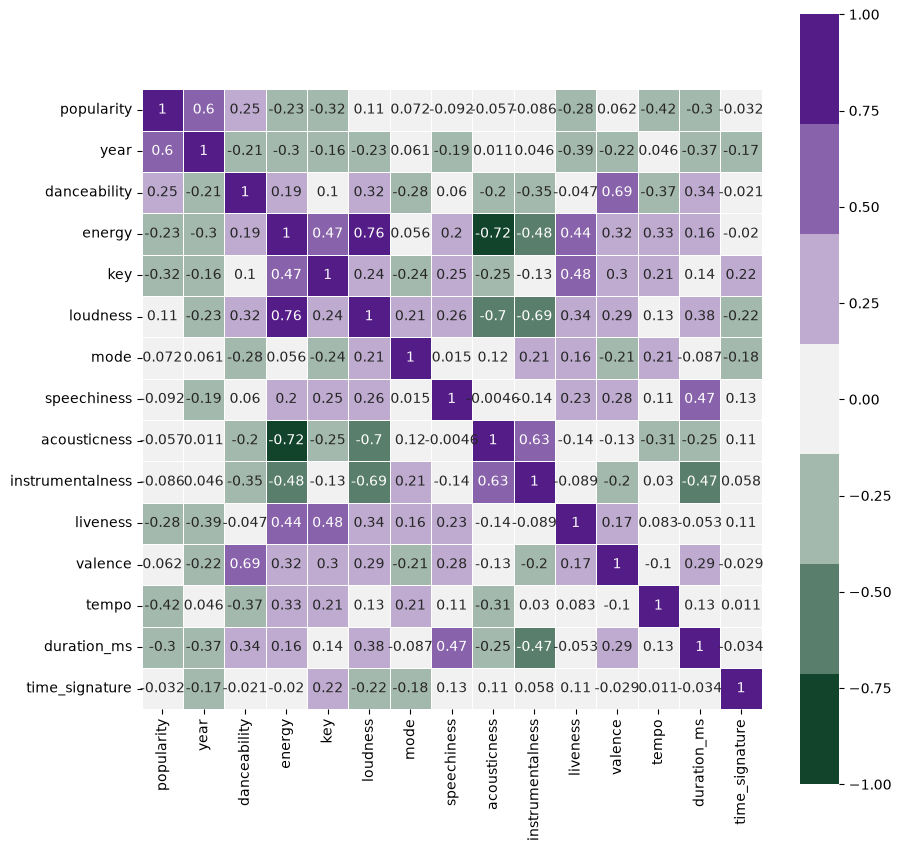

In [67]:
plt.figure(figsize=(10, 10))

sns.heatmap(
    df2.corr(),
    vmin=-1,
    vmax=1,
    cmap=sns.diverging_palette(145, 280, s=85, l=25, n=7),
    annot=True,
    square=True,
    linewidths=.5
)

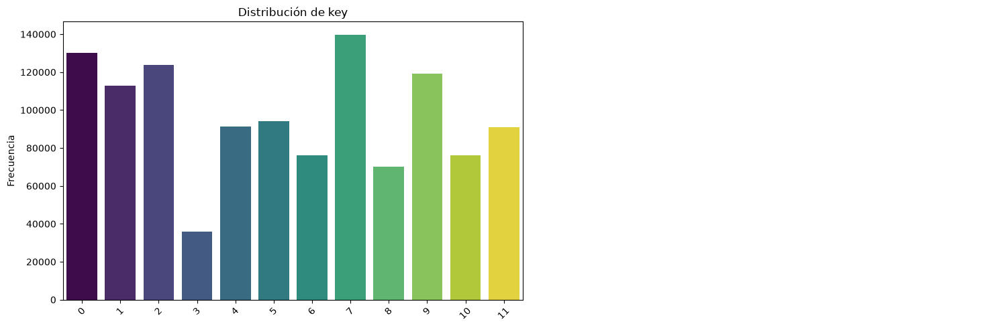

In [70]:
pinta_distribucion_categoricas(archivo, columnas_categoricas=['key'] )

/home/pussyxxxxpounder24/.local/lib/python3.14/site-packages/seaborn/axisgrid.py:123: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  self._figure.tight_layout(*args, **kwargs)


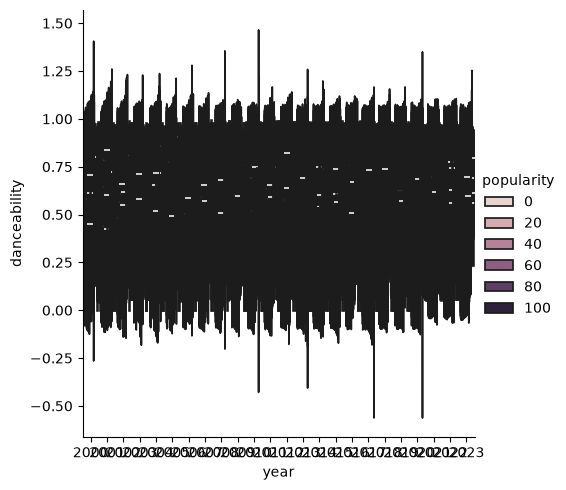

In [ ]:
sns.catplot(x="year", y="popularity", hue="danceability", kind="violin", split = True, data=archivo);

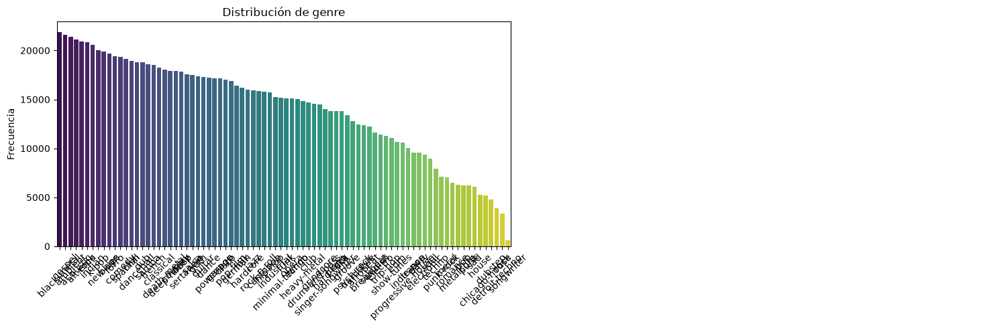

In [ ]:
pinta_distribucion_categoricas(archivo, ['genre'])#distribuvion completamente logaritmica fr fr